# КП — Методи обчислювального інтелекту

Не для кожної задачі є точна формула чи алгоритм. Тоді рішення будують із нечітких правил, налаштовують за даними або шукають еволюційно. Кожна частина практикуму показує один такий метод:

| Частина | Задача | Коли беруть такий метод | Кроки |
|---|---|---|---|
| 1. Нечітка система | оцінка за словесними правилами | є знання експерта словами («якщо дохід високий і стаж середній, то…»), а даних мало | 1–4 |
| 2. Нейро-нечітка модель | прогноз виходу за даними | є дані, але потрібна модель із зрозумілими правилами, а не «чорна скринька» | 5–8 |
| 3. Генетичний алгоритм | розподіл об'єктів між бригадами | треба знайти найкращий варіант серед величезної кількості, а похідних немає і перебір неможливий | 9–11 |

Ноутбук нижче проходить кожен метод на одній задачі. Він не охоплює всіх різновидів методів (є, наприклад, модель Сугено першого порядку, інші функції належності чи оператори ГА), а частину коду дано готовою: ядро моделі Сугено, субтрактивну кластеризацію, запуск ГА, оцінку й ремонт плану, точний розв'язувач. Суть кроків — зібрати метод із заданих частин і прочитати його результат. Документація бібліотек: [scikit-fuzzy](https://scikit-fuzzy.github.io/scikit-fuzzy/) і [PyGAD](https://pygad.readthedocs.io/).

Шаблон веде покроково: у кожному кроці — навіщо він і що зробити, у клітинці з `TODO` — ваш код. Клітинки без `TODO` вже готові, їх лише запустити. Умова вашого варіанта — у `variants/<варіант>/README.md`, дані — у `variants/<варіант>/sample.csv`.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import skfuzzy as fuzz
from skfuzzy import control as ctrl
from sklearn.model_selection import train_test_split
from scipy.optimize import minimize, milp, LinearConstraint, Bounds
import pygad

## Частина 1. Нечітка система

### 1. Підсистема

Лінгвістична змінна — величина, значення якої описують словами: «низький», «середній», «високий». Кожне слово — нечітка множина з функцією належності: ступінь від 0 до 1, з яким число належить терму. Сусідні трикутні терми перекриваються, тож число належить двом термам одночасно з різними ступенями.

`automf(3, names=TERMS)` ділить діапазон на три трикутні терми з вершинами на лівому краї, посередині й на правому краї. Правило «ЯКЩО x низький І y високий ТО z середній» пов'язує терми входів із термом виходу, а таблиця 3 × 3 з README — це дев'ять таких правил.

Напишіть функцію `fuzzy_system(x_range, y_range, z_range, table, method)`, яка повертає `ctrl.ControlSystemSimulation` однієї підсистеми:

1. `x_range`, `y_range`, `z_range` — пари (min, max) з README варіанта; кожна змінна — на `np.linspace(min, max, 201)`.
2. `x` і `y` — `ctrl.Antecedent` з назвами `"x"` і `"y"`, `z` — `ctrl.Consequent` з назвою `"z"` і `defuzzify_method=method`.
3. Кожній змінній — `automf(3, names=TERMS)`.
4. `table` — таблиця правил із README як список рядків: `table[i][j]` — терм `z` для `x = TERMS[i]` і `y = TERMS[j]`. У README рядки таблиці — терми `x`, стовпці — терми `y` (заголовок «x \ y»). З неї — дев'ять правил `ctrl.Rule(x[TERMS[i]] & y[TERMS[j]], z[table[i][j]])`, з них — `ctrl.ControlSystem`.

In [2]:
TERMS = ["низький", "середній", "високий"]


def fuzzy_system(x_range, y_range, z_range, table, method):
    x = ctrl.Antecedent(np.linspace(*x_range, 201), "x")
    y = ctrl.Antecedent(np.linspace(*y_range, 201), "y")
    z = ctrl.Consequent(np.linspace(*z_range, 201), "z", defuzzify_method=method)
    for variable in (x, y, z):
        variable.automf(3, names=TERMS)
    rules = [ctrl.Rule(x[TERMS[i]] & y[TERMS[j]], z[table[i][j]]) for i in range(3) for j in range(3)]
    return ctrl.ControlSystemSimulation(ctrl.ControlSystem(rules))

### 2. Виведення за Мамдані

Система перетворює числа на входах у число на виході за п'ять етапів:

| Етап | Що відбувається |
|---|---|
| фазифікація | для кожного входу — ступінь належності до кожного терма |
| агрегування умов | сила правила — мінімум ступенів його умов, бо умови з'єднано «І» |
| активізація | терм виходу кожного правила зрізається на рівні сили правила |
| акумуляція | зрізані терми всіх правил об'єднуються максимумом в одну фігуру |
| дефазифікація | фігура перетворюється на число |

Центроїд — абсциса центру ваги фігури: враховує всю фігуру. Середнє максимумів — середина її найвищої ділянки: враховує лише найсильніше правило. Тому на тій самій фігурі вони дають різні числа.

1. Впишіть межі змінних і таблиці правил трьох підсистем зі свого README.
2. Порахуйте вихід 1.1 і вихід 1.2 у точці для кроку 2 з `method="centroid"`: `sim.input["x"]`, `sim.input["y"]`, `sim.compute()`, `sim.output["z"]`. «Подати входи й отримати вихід» знадобиться ще не раз, тож зробіть це функцією.
3. Подайте ці два числа на входи 1.3 — вихід 1.1 на `x`, вихід 1.2 на `y` — і порахуйте вихід 1.3 двічі: з `method="centroid"` і з `method="mom"`. 1.1 і 1.2 перераховувати не треба.
4. Виведіть виходи 1.1, 1.2 і обидва виходи 1.3.

In [3]:
RANGES_11 = ((0, 60), (-10, 20), (0, 10))     # опади, температура → швидкість танення снігу
RANGES_12 = ((0, 12), (0, 500), (0, 100))     # рівень води, площа басейну → обсяг спуску води
RANGES_13 = ((0, 10), (0, 100), (0, 8))       # танення, спуск → очікуваний рівень повені

TABLE_11 = [["низький", "низький", "середній"],
            ["низький", "середній", "високий"],
            ["середній", "високий", "високий"]]
TABLE_12 = [row[:] for row in TABLE_11]
TABLE_13 = [row[:] for row in TABLE_11]


def infer(ranges, table, method, x_value, y_value):
    sim = fuzzy_system(*ranges, table, method)
    sim.input["x"] = x_value
    sim.input["y"] = y_value
    sim.compute()
    return sim.output["z"]


out_11 = infer(RANGES_11, TABLE_11, "centroid", 33, 18.5)
out_12 = infer(RANGES_12, TABLE_12, "centroid", 10.2, 300)
out_13_centroid = infer(RANGES_13, TABLE_13, "centroid", out_11, out_12)
out_13_mom = infer(RANGES_13, TABLE_13, "mom", out_11, out_12)

print(f"1.1 швидкість танення снігу: {out_11:.3f} см/добу")
print(f"1.2 обсяг спуску води: {out_12:.3f} млн м³")
print(f"1.3 рівень повені: центроїд {out_13_centroid:.3f} м, середнє максимумів {out_13_mom:.3f} м")

1.1 швидкість танення снігу: 7.382 см/добу
1.2 обсяг спуску води: 62.439 млн м³
1.3 рівень повені: центроїд 4.431 м, середнє максимумів 4.000 м


Щоб побачити, чому методи дали різні числа, подивіться, які правила 1.3 спрацювали в цій точці.

Виведіть силу кожного з дев'яти правил 1.3 за таблицею з README, від більшої до меншої. Входи 1.3 — виходи 1.1 і 1.2 з попередньої клітинки.

- ступінь належності входу до терма — `fuzz.interp_membership(universe, mf, значення)`;
- трикутники `automf` — `fuzz.trimf(universe, [a, a, m])`, `[a, m, b]` і `[m, b, b]`, де `a` і `b` — межі змінної, `m` — середина;
- сила правила — мінімум ступенів `x` і `y`; правила із силою 0 не спрацювали.

In [4]:
def memberships(value, value_range):
    low, high = value_range
    universe = np.linspace(low, high, 201)
    middle = (low + high) / 2
    shapes = {"низький": [low, low, middle], "середній": [low, middle, high], "високий": [middle, high, high]}
    return {term: float(fuzz.interp_membership(universe, fuzz.trimf(universe, abc), value)) for term, abc in shapes.items()}


mu_x = memberships(out_11, RANGES_13[0])
mu_y = memberships(out_12, RANGES_13[1])
strengths = pd.DataFrame([
    {"x (танення)": term_x, "y (спуск)": term_y, "z (повінь)": TABLE_13[i][j], "сила": min(mu_x[term_x], mu_y[term_y])}
    for i, term_x in enumerate(TERMS) for j, term_y in enumerate(TERMS)
])
print(strengths.sort_values("сила", ascending=False).round(3).to_string(index=False))

x (танення) y (спуск) z (повінь)  сила
   середній  середній   середній 0.524
    високий  середній    високий 0.476
   середній   високий    високий 0.249
    високий   високий    високий 0.249
    низький   низький    низький 0.000
   середній   низький    низький 0.000
    низький   високий   середній 0.000
    низький  середній    низький 0.000
    високий   низький   середній 0.000


### 3. Поверхня

Поверхня показує вихід підсистеми для всіх пар входів одразу. Пологі ділянки — зони, де переважає одне правило; схили — переходи між правилами.

Побудуйте поверхню підсистеми 1.3: вихід (центроїд) на сітці 21 × 21 значень `x` і `y` у їхніх межах. Намалюйте її як `plt.contourf` або 3D-поверхню й підпишіть осі назвами змінних. `plt.contourf(xs, ys, Z)` чекає `Z[i, j]` для `y = ys[i]` і `x = xs[j]`. Зробіть це функцією від таблиці правил: у кроці 4 таку саму поверхню треба побудувати для зміненої таблиці.

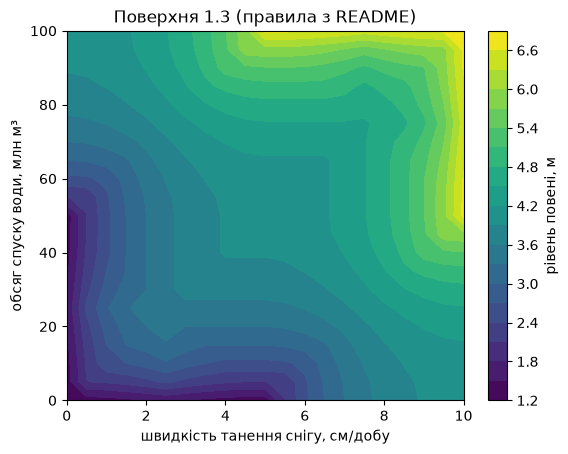

In [5]:
def surface(table):
    xs = np.linspace(*RANGES_13[0], 21)
    ys = np.linspace(*RANGES_13[1], 21)
    sim = fuzzy_system(*RANGES_13, table, "centroid")
    Z = np.zeros((len(ys), len(xs)))
    for i, y_value in enumerate(ys):
        for j, x_value in enumerate(xs):
            sim.input["x"] = x_value
            sim.input["y"] = y_value
            sim.compute()
            Z[i, j] = sim.output["z"]
    return xs, ys, Z


def plot_surface(xs, ys, Z, title, label="рівень повені, м"):
    plt.contourf(xs, ys, Z, levels=20, cmap="viridis")
    plt.colorbar(label=label)
    plt.xlabel("швидкість танення снігу, см/добу")
    plt.ylabel("обсяг спуску води, млн м³")
    plt.title(title)
    plt.show()


xs, ys, Z_old = surface(TABLE_13)
plot_surface(xs, ys, Z_old, "Поверхня 1.3 (правила з README)")

### 4. Одне правило

Кожне правило керує виходом лише там, де воно спрацьовує. Тому зміна однієї клітинки таблиці — одного правила — змінює поверхню лише там, де сила цього правила більша за 0. Для правила з крайніми термами це кут поверхні, для правила із середніми термами — більша її частина, бо середній терм покриває весь діапазон, крім країв.

1. Змініть правило 1.3, як сказано в README для кроку 4. Змінюйте копію таблиці (`[row[:] for row in table]`): стара ще потрібна для порівняння, а зміна вкладеного списку на місці зачепить і її.
2. Порахуйте вихід 1.3 у тій самій точці з `method="centroid"` і з `method="mom"` та виведіть поруч зі старими.
3. Побудуйте поверхню зі зміненим правилом і різницю двох поверхонь.

центроїд: було 4.431, стало 6.462 м
середнє максимумів: було 4.000, стало 7.040 м


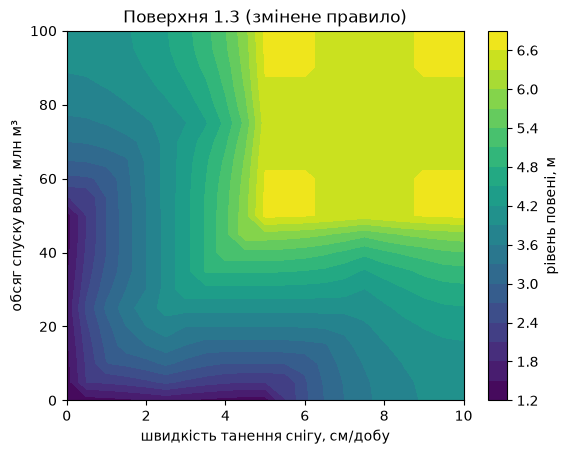

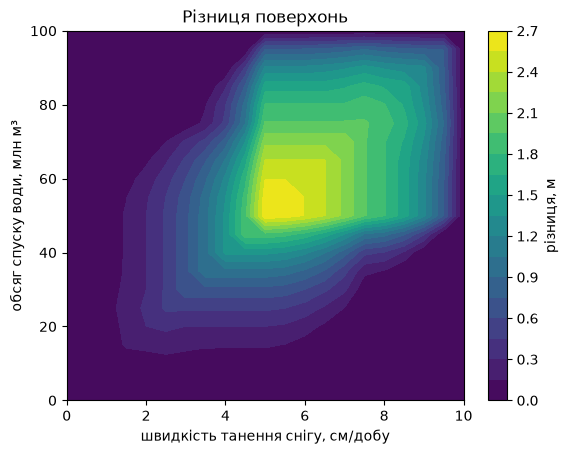

In [6]:
TABLE_13_NEW = [row[:] for row in TABLE_13]
TABLE_13_NEW[1][1] = "високий"   # рядок «середній», стовпець «середній»

new_centroid = infer(RANGES_13, TABLE_13_NEW, "centroid", out_11, out_12)
new_mom = infer(RANGES_13, TABLE_13_NEW, "mom", out_11, out_12)
print(f"центроїд: було {out_13_centroid:.3f}, стало {new_centroid:.3f} м")
print(f"середнє максимумів: було {out_13_mom:.3f}, стало {new_mom:.3f} м")

_, _, Z_new = surface(TABLE_13_NEW)
plot_surface(xs, ys, Z_new, "Поверхня 1.3 (змінене правило)")
plot_surface(xs, ys, Z_new - Z_old, "Різниця поверхонь", label="різниця, м")

## Частина 2. Нейро-нечітка модель

### 5. Дані

Модель Сугено нульового порядку складається з правил «ЯКЩО входи близькі до центру правила ТО y = число». Вихід — середнє висновків правил, зважене ступенями активації. Нейро-нечіткою її роблять параметри — центри, ширини й висновки, — які підбирають за даними, як ваги мережі.

Похибка — RMSE в одиницях виходу. Точка відліку — прогноз середнім значенням навчальної частини: модель, гірша за нього на тестовій частині, нічого корисного не навчилася. Входи й вихід нормують у [0, 1] за навчальною частиною, щоб центри й ширини правил мали однаковий масштаб.

1. Завантажте `sample.csv` свого варіанта: `X` — усі колонки, крім останньої, `y` — остання. Поділ задано нижче.
2. Нормуйте мінімумом і максимумом навчальної частини, для кожного входу окремо (`X_tr.min(axis=0)`): `x_tr`, `x_te` — входи, `t_tr`, `t_te` — вихід. Для тестової частини теж беруть мінімум і максимум навчальної, тож її значення можуть трохи виходити за [0, 1] — це нормально.
3. `y_span = y_tr.max() - y_tr.min()`: на нього множать нормовану похибку, щоб отримати одиниці виходу.
4. Виведіть розміри частин і RMSE прогнозу середнім `y_tr` на навчальній і тестовій частинах.

In [7]:
sample = pd.read_csv("data/sample.csv")
X = sample.iloc[:, :-1]
y = sample.iloc[:, -1]

X_tr, X_te, y_tr, y_te = train_test_split(X.to_numpy(), y.to_numpy(), test_size=0.25, random_state=0)

x_min, x_max = X_tr.min(axis=0), X_tr.max(axis=0)
x_tr = (X_tr - x_min) / (x_max - x_min)
x_te = (X_te - x_min) / (x_max - x_min)

y_min = y_tr.min()
y_span = y_tr.max() - y_tr.min()
t_tr = (y_tr - y_min) / y_span
t_te = (y_te - y_min) / y_span

rmse_mean_tr = float(np.sqrt(np.mean((y_tr - y_tr.mean()) ** 2)))
rmse_mean_te = float(np.sqrt(np.mean((y_te - y_tr.mean()) ** 2)))
print("навчальна:", X_tr.shape, "| тестова:", X_te.shape)
print(f"RMSE прогнозу середнім: навчальна {rmse_mean_tr:.3f}, тестова {rmse_mean_te:.3f}")

навчальна: (45, 4) | тестова: (15, 4)
RMSE прогнозу середнім: навчальна 1.125, тестова 0.861


In [8]:
def unpack(theta, c):
    k = c * x_tr.shape[1]
    return theta[:k].reshape(c, -1), np.exp(theta[k:2 * k]).reshape(c, -1), theta[2 * k:]


def activation(theta, x, c):
    centers, widths, _ = unpack(theta, c)
    z = -0.5 * (((x[:, None, :] - centers[None]) / widths[None]) ** 2).sum(axis=2)
    e = np.exp(z - z.max(axis=1, keepdims=True))
    return e / e.sum(axis=1, keepdims=True)


def rmse(theta, x, t, c):
    return float(np.sqrt(np.mean((activation(theta, x, c) @ unpack(theta, c)[2] - t) ** 2)))


def errors(theta, c):
    return rmse(theta, x_tr, t_tr, c) * y_span, rmse(theta, x_te, t_te, c) * y_span


def pack(centers, widths):
    c = len(centers)
    theta = np.concatenate([np.ravel(centers), np.log(np.ravel(widths)), np.zeros(c)])
    w = activation(theta, x_tr, c)
    theta[2 * c * x_tr.shape[1]:] = np.linalg.solve(w.T @ w + 1e-8 * np.eye(c), w.T @ t_tr)
    return theta


def tune(theta, c):
    n = c * x_tr.shape[1]
    bounds = [(-0.05, 1.05)] * n + [(np.log(0.08), np.log(0.8))] * n + [(-0.05, 1.05)] * c
    res = minimize(rmse, np.clip(theta, *np.array(bounds).T), args=(x_tr, t_tr, c),
                   method="L-BFGS-B", bounds=bounds, options={"maxiter": 2000})
    return res.x

Що робить готовий код вище:

| Функція | Що робить |
|---|---|
| `activation` | ступені активації правил: гаусова функція належності на кожен вхід, добуток по входах, нормування до суми 1 (обчислюється через експоненту різниці, щоб не ділити на машинний нуль) |
| `pack` | збирає параметри правил в один вектор; висновки правил рахує методом найменших квадратів, як прямий хід ANFIS |
| `tune` | налаштовує всі параметри мінімізацією RMSE на навчальній частині; центри не виходять за межі даних, ширина — від 0.08 до 0.8 діапазону |
| `errors` | RMSE на навчальній і тестовій частинах в одиницях виходу |

### 6. Субтрактивна кластеризація

Щоб отримати правила з даних, точки навчальної частини кластеризують: кожен кластер стає правилом. Субтрактивна кластеризація сама визначає, скільки кластерів. Кожна точка отримує потенціал — скільки інших точок поблизу. Точка з найбільшим потенціалом стає центром, потенціал її сусідів у межах радіуса впливу `ra` зменшується, і пошук повторюється, доки потенціал не впаде нижче порогу. Малий радіус — багато дрібних кластерів, великий — кілька великих. Так будує базу правил редактор ANFIS у Matlab.

Субтрактивна кластеризація сама обирає кількість правил, але ця кількість сильно залежить від `ra`, а яке `ra` правильне, метод не підказує. Тому далі правила будує c-means із заданою кількістю, а в кроці 8 перевіряють, скільки правил справді потрібно.

Для `ra` = 0.3, 0.5 і 0.8 запустіть `subclust` на `np.column_stack([x_tr, t_tr])` і виведіть, скільки правил дає кожен радіус — стільки рядків у результаті.

In [9]:
def subclust(data, ra, accept=0.5, reject=0.15):
    a, b = 4 / ra ** 2, 4 / (1.5 * ra) ** 2
    potential = np.exp(-a * ((data[:, None, :] - data[None, :, :]) ** 2).sum(-1)).sum(1)
    first, centers = potential.max(), []
    while True:
        k = int(potential.argmax())
        top = potential[k]
        if top < reject * first:
            break
        if top < accept * first:
            nearest = min(np.sqrt(((data[k] - data[c]) ** 2).sum()) for c in centers)
            if nearest / ra + top / first < 1:
                potential[k] = 0
                continue
        centers.append(k)
        potential = np.maximum(potential - top * np.exp(-b * ((data - data[k]) ** 2).sum(1)), 0)
    return data[centers]

In [10]:
data = np.column_stack([x_tr, t_tr])
for ra in (0.3, 0.5, 0.8):
    print(f"ra = {ra}: правил {len(subclust(data, ra))}")

ra = 0.3: правил 19
ra = 0.5: правил 8
ra = 0.8: правил 2


### 7. Правила з c-means і налаштування

Нечітка кластеризація c-means не визначає кількість кластерів сама: її задають. Зате кожна точка належить кожному кластеру зі своїм ступенем `u`. Кластеризують разом входи й вихід, бо правило має об'єднувати точки, схожі і за входами, і за виходом. Центр правила — перші координати центру кластера, тобто вхідні; ширина на кожен вхід — стандартне відхилення точок від центру, зважене квадратами ступенів `u`.

Налаштування підганяє центри, ширини й висновки під навчальну частину. У трьох правил на чотири входи 27 параметрів, а навчальних рядків — кілька десятків. Такій моделі легко запам'ятати навчальні точки разом із їхнім шумом.

1. Функція `cmeans_rules(c)` нижче майже готова: допишіть ширини. Ширина правила `k` на кожен вхід — `np.sqrt((u[k] ** 2 @ (x_tr - centers[k]) ** 2) / (u[k] ** 2).sum())`.
2. Побудуйте три правила `theta = cmeans_rules(3)` і налаштуйте їх: `theta_tuned = tune(theta, 3)`.
3. Виведіть таблицю RMSE на навчальній і тестовій частинах: прогноз середнім, правила до налаштування (`errors(theta, 3)`) і після.

In [11]:
def cmeans_rules(c):
    cntr, u, *_ = fuzz.cluster.cmeans(np.column_stack([x_tr, t_tr]).T, c=c, m=2.0, error=1e-6, maxiter=1000, seed=0)
    centers = cntr[:, :x_tr.shape[1]]
    widths = np.array([np.sqrt((u[k] ** 2 @ (x_tr - centers[k]) ** 2) / (u[k] ** 2).sum()) for k in range(c)])
    return pack(centers, np.clip(widths, 0.08, 0.8))


theta = cmeans_rules(3)
theta_tuned = tune(theta, 3)

rows = [
    {"модель": "прогноз середнім", "навчальна": rmse_mean_tr, "тестова": rmse_mean_te},
    {"модель": "3 правила, до налаштування", **dict(zip(["навчальна", "тестова"], errors(theta, 3)))},
    {"модель": "3 правила, після налаштування", **dict(zip(["навчальна", "тестова"], errors(theta_tuned, 3)))},
]
print(pd.DataFrame(rows).round(3).to_string(index=False))

                       модель  навчальна  тестова
             прогноз середнім      1.125    0.861
   3 правила, до налаштування      1.056    0.638
3 правила, після налаштування      0.691    1.201


### 8. Кількість правил

Кожне нове правило додає параметри. Навчальна похибка від цього зазвичай спадає, а тестова — лише доки нові правила описують закономірність, а не шум. Що більший розрив між тестовою і навчальною похибкою, то сильніше перенавчання.

Для кількості правил від 2 до 6 побудуйте правила `cmeans_rules(c)` і налаштуйте їх. Виведіть таблицю «кількість правил, RMSE на навчальній і тестовій частинах» і побудуйте обидві криві на одному графіку разом із горизонтальною лінією RMSE прогнозу середнім на тестовій частині. Налаштування може зупинитися в локальному мінімумі, тож на кількох десятках рядків криві бувають нерівними; порівнюйте розрив при 2 і при 6 правилах. `theta` і `theta_tuned` із кроку 7 не перезаписуйте: їх використовує самоперевірка.

 правил  навчальна  тестова
      2      0.823    0.598
      3      0.691    1.201
      4      0.574    0.928
      5      0.439    1.210
      6      0.292    1.053


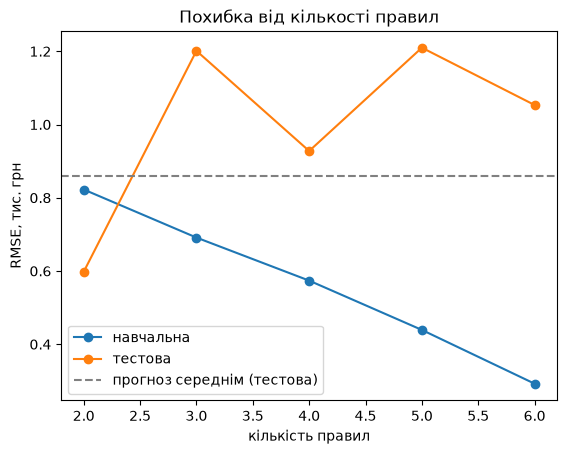

In [12]:
rule_rows = []
for c in range(2, 7):
    train_error, test_error = errors(tune(cmeans_rules(c), c), c)
    rule_rows.append({"правил": c, "навчальна": train_error, "тестова": test_error})
rules_table = pd.DataFrame(rule_rows)
print(rules_table.round(3).to_string(index=False))

plt.plot(rules_table["правил"], rules_table["навчальна"], marker="o", label="навчальна")
plt.plot(rules_table["правил"], rules_table["тестова"], marker="o", label="тестова")
plt.axhline(rmse_mean_te, color="gray", linestyle="--", label="прогноз середнім (тестова)")
plt.xlabel("кількість правил")
plt.ylabel("RMSE, тис. грн")
plt.title("Похибка від кількості правил")
plt.legend()
plt.show()

## Частина 3. Розподіл бригад

### 9. Задача й жадібний алгоритм

Об'єкти — рядки `sample.csv`. Кожен об'єкт можна доручити одній із трьох бригад або не брати в план. Час на об'єкт і фонд часу бригад — у README варіанта, втрати, яких уникає обслуговування, — остання колонка. Треба максимізувати суму втрат, яких уникнули, так, щоб жодна бригада не вийшла за свій фонд. Це задача про кілька рюкзаків: перебором її не розв'язати, бо варіантів плану 4 в степені кількості об'єктів.

Жадібний алгоритм бере об'єкти за спаданням відношення «втрати / час» і кладе кожен у першу бригаду, де він ще вміщується, перевіряючи бригади 1, 2, 3 по черзі. Він швидкий, але може зайняти місце, яке краще було б віддати двом іншим об'єктам.

План записується як масив: для кожного об'єкта 0 — не обслуговувати, 1–3 — номер бригади.

1. Впишіть фонд часу трьох бригад і дільник із README варіанта. Порахуйте `t = 0.5 + contracted_power_kw / TIME_DIV` для кожного рядка `sample`; `v` — остання колонка. Беріть усі рядки `sample.csv`, а не лише навчальну частину з кроку 5.
2. Складіть план жадібним алгоритмом, назвіть його `plan_greedy` і виведіть суму, завантаження й перевищення. Порядок об'єктів за спаданням `v / t` дає `np.argsort(-(v / t))`.

Функції нижче вже готові: `load` — завантаження бригад, `overflow` — сумарне перевищення фондів, `value` — сума плану, `repair` — ремонт плану.

In [13]:
FUND = (9, 6, 3)
TIME_DIV = 12

t = 0.5 + sample["contracted_power_kw"].to_numpy() / TIME_DIV
v = sample.iloc[:, -1].to_numpy()
print("об'єктів:", len(t), "| сумарний час:", round(t.sum(), 2), "год | фонд бригад:", sum(FUND), "год")

об'єктів: 60 | сумарний час: 114.02 год | фонд бригад: 18 год


In [14]:
def load(plan):
    return [float(t[plan == b].sum()) for b in (1, 2, 3)]


def overflow(plan):
    return float(sum(max(0.0, used - f) for used, f in zip(load(plan), FUND)))


def value(plan):
    return float(v[plan > 0].sum())


def repair(plan):
    plan = np.asarray(plan, int).copy()
    for b, f in enumerate(FUND, start=1):
        idx = np.flatnonzero(plan == b)
        used = t[idx].sum()
        for i in idx[np.argsort(v[idx] / t[idx])]:
            if used <= f + 1e-9:
                break
            plan[i], used = 0, used - t[i]
    return plan

In [15]:
def show(name, plan):
    print(f"{name}: сума {value(plan):.3f} тис. грн, завантаження {np.round(load(plan), 2)}, перевищення {overflow(plan):.3f} год")


plan_greedy = np.zeros(len(t), dtype=int)
used = [0.0, 0.0, 0.0]
for i in np.argsort(-(v / t)):
    for b in range(3):
        if used[b] + t[i] <= FUND[b] + 1e-9:
            plan_greedy[i] = b + 1
            used[b] += t[i]
            break

show("жадібний алгоритм", plan_greedy)

жадібний алгоритм: сума 34.829 тис. грн, завантаження [8.34 5.67 2.81], перевищення 0.000 год


### 10. Генетичний алгоритм

Генетичний алгоритм тримає популяцію планів. Кожен план оцінюється пристосованістю. Турнірна селекція відбирає кращих із випадкових трійок, рівномірне схрещування бере кожен ген від одного з двох батьків, мутація випадково змінює кілька генів, а чотири найкращі плани переходять у нове покоління без змін. Похідні не потрібні — досить уміти оцінити план.

Обмеження фонду в суму не входить, тож із ним поводяться окремо:

| Спосіб | Як | Ризик |
|---|---|---|
| штраф | пристосованість = сума − 10 · перевищення | малий виступ за фонд може окупитися, і найкращий план буде недопустимим |
| ремонт | перед оцінкою з переповненої бригади знімають найменш вигідні об'єкти; оцінюють уже допустимий план | пошук іде лише серед того, що вміє полагодити ремонт |

Функція `run_ga(fitness)` нижче запускає ГА з параметрами практикуму й повертає найкращий план. Функція пристосованості для `pygad` має вигляд `lambda ga, sol, idx: ...`.

1. ГА з ремонтом: пристосованість — `value(repair(sol))`. Найкращий план полагодьте `repair` і назвіть `plan_repair`.
2. ГА зі штрафом: пристосованість — `value(sol) - 10 * overflow(sol)`. Найкращий план назвіть `plan_penalty`, без ремонту.
3. Для обох планів виведіть суму, завантаження й перевищення.

In [16]:
def run_ga(fitness):
    ga = pygad.GA(num_generations=250, sol_per_pop=120, num_parents_mating=60, num_genes=len(t), gene_type=int,
                  gene_space=[0, 1, 2, 3], fitness_func=fitness, parent_selection_type="tournament", K_tournament=3,
                  crossover_type="uniform", mutation_type="random", mutation_num_genes=max(1, len(t) // 20),
                  keep_elitism=4, random_seed=0, suppress_warnings=True)
    ga.run()
    return np.asarray(ga.best_solution()[0], int)


plan_repair = repair(run_ga(lambda ga, sol, idx: value(repair(sol))))
show("ГА з ремонтом", plan_repair)

ГА з ремонтом: сума 36.471 тис. грн, завантаження [8.99 5.93 2.99], перевищення 0.000 год


In [17]:
plan_penalty = run_ga(lambda ga, sol, idx: value(sol) - 10 * overflow(sol))
show("ГА зі штрафом", plan_penalty)

ГА зі штрафом: сума 27.584 тис. грн, завантаження [7.31 5.36 3.01], перевищення 0.006 год


### 11. Точний оптимум

Для кількох десятків об'єктів задачу можна розв'язати точно цілочисловим лінійним програмуванням. Готова функція нижче повертає найкращий можливий план. На практиці такий розв'язувач є не завжди, а в більших задачах він не встигає — тоді й беруть ГА.

Порахуйте `plan_optimum = optimum()` і виведіть таблицю: жадібний алгоритм, ГА з ремонтом, ГА зі штрафом, оптимум — сума, завантаження бригад, перевищення і сума у відсотках від оптимуму.

In [18]:
def optimum():
    n = len(t)
    rows = [np.concatenate([t if b == k else np.zeros(n) for k in range(3)]) for b in range(3)]
    rows += [np.tile(np.eye(n)[i], 3) for i in range(n)]
    res = milp(-np.tile(v, 3), integrality=np.ones(3 * n), bounds=Bounds(0, 1),
               constraints=LinearConstraint(np.array(rows), [0] * (3 + n), list(FUND) + [1] * n))
    return (np.arange(1, 4)[:, None] * np.round(res.x).reshape(3, n)).sum(0).astype(int)

In [19]:
plan_optimum = optimum()
best = value(plan_optimum)

plans = {
    "жадібний алгоритм": plan_greedy,
    "ГА з ремонтом": plan_repair,
    "ГА зі штрафом": plan_penalty,
    "оптимум": plan_optimum,
}
plans_table = pd.DataFrame([
    {"план": name, "сума, тис. грн": round(value(plan), 3), "завантаження, год": np.round(load(plan), 2).tolist(),
     "перевищення, год": round(overflow(plan), 3), "% оптимуму": round(100 * value(plan) / best, 1)}
    for name, plan in plans.items()
])
print(plans_table.to_string(index=False))

             план  сума, тис. грн  завантаження, год  перевищення, год  % оптимуму
жадібний алгоритм          34.829 [8.34, 5.67, 2.81]             0.000        95.5
    ГА з ремонтом          36.471 [8.99, 5.93, 2.99]             0.000       100.0
    ГА зі штрафом          27.584 [7.31, 5.36, 3.01]             0.006        75.6
          оптимум          36.471  [9.0, 5.96, 2.96]             0.000       100.0


### 12. Самоперевірка й збереження

Якщо якась перевірка падає, поверніться до відповідного кроку.

In [20]:
plan = pd.DataFrame({"row": np.arange(len(t)), "brigade": np.asarray(plan_repair, int)})

assert len(t) == len(v) == len(plan) == len(sample), "t, v і план мають мати рядок на кожен об'єкт sample.csv"
assert tuple(FUND) in [(6, 6, 6), (7, 6, 5), (7, 7, 4), (8, 5, 5), (8, 6, 4), (8, 7, 3), (9, 5, 4), (9, 6, 3), (10, 4, 4), (10, 5, 3)] and TIME_DIV in (8, 10, 12), "фонди бригад і дільник — з README варіанта, фонди в порядку бригад 1, 2, 3"
assert plan["brigade"].isin([0, 1, 2, 3]).all(), "бригада — 0, 1, 2 або 3"
assert overflow(plan_repair) == 0, "план ГА з ремонтом перевищує фонд часу"
assert value(plan_repair) >= value(plan_greedy) - 1e-9, "ГА з ремонтом гірший за жадібний алгоритм: перевірте параметри з кроку 10"
assert value(plan_repair) <= value(plan_optimum) + 1e-9, "сума більша за оптимум: перевірте t, v і FUND"
assert errors(theta_tuned, 3)[0] < errors(theta, 3)[0], "налаштування не знизило навчальну похибку"

plan.to_csv("plan.csv", index=False)
print("усе гаразд: сума", round(value(plan_repair), 3), "з оптимуму", round(value(plan_optimum), 3))

усе гаразд: сума 36.471 з оптимуму 36.471
